<a href="https://colab.research.google.com/github/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/mao_na_massa_5.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Colab-F9AB00?labelColor=F9AB00&logo=googlecolab&logoColor=white" alt="Abrir no Colab"/></a> <a href="https://github.com/cleberfmodesto/classificacao_xgboost/blob/main/Atividades/mao_na_massa_5.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-GitHub-0969DA?labelColor=0969DA&logo=github&logoColor=white" alt="Abrir GitHub"/></a> <a href="https://github.com/codespaces/new?repo=cleberfmodesto/classificacao_xgboost&ref=main" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Codespaces-1F883D?labelColor=1F883D&logo=github&logoColor=white" alt="Abrir no Codespaces"/></a>

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/vqrca/heart_disease/main/Data/heart_2020_cleaned.csv')

In [ ]:
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  object 
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  object 
 3   AlcoholDrinking   319795 non-null  object 
 4   Stroke            319795 non-null  object 
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  object 
 8   Sex               319795 non-null  object 
 9   AgeCategory       319795 non-null  object 
 10  Race              319795 non-null  object 
 11  Diabetic          319795 non-null  object 
 12  PhysicalActivity  319795 non-null  object 
 13  GenHealth         319795 non-null  object 
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  object 
 16  KidneyDisease     31

In [ ]:
df.duplicated().sum()

18078

In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df.reset_index(drop=True, inplace=True)

In [6]:
from sklearn.preprocessing import LabelEncoder

# Codificação de rótulos para colunas binárias
colunas_binarias = ['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 'DiffWalking',
                  'PhysicalActivity', 'Asthma', 'KidneyDisease', 'SkinCancer']

label_encoder = LabelEncoder()
for col in colunas_binarias:
    df[col] = label_encoder.fit_transform(df[col])

In [ ]:
df

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,0,16.60,1,0,0,3.0,30.0,0,Female,55-59,White,Yes,1,Very good,5.0,1,0,1
1,0,20.34,0,0,1,0.0,0.0,0,Female,80 or older,White,No,1,Very good,7.0,0,0,0
2,0,26.58,1,0,0,20.0,30.0,0,Male,65-69,White,Yes,1,Fair,8.0,1,0,0
3,0,24.21,0,0,0,0.0,0.0,0,Female,75-79,White,No,0,Good,6.0,0,0,1
4,0,23.71,0,0,0,28.0,0.0,1,Female,40-44,White,No,1,Very good,8.0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301712,1,27.41,1,0,0,7.0,0.0,1,Male,60-64,Hispanic,Yes,0,Fair,6.0,1,0,0
301713,0,29.84,1,0,0,0.0,0.0,0,Male,35-39,Hispanic,No,1,Very good,5.0,1,0,0
301714,0,24.24,0,0,0,0.0,0.0,0,Female,45-49,Hispanic,No,1,Good,6.0,0,0,0
301715,0,32.81,0,0,0,0.0,0.0,0,Female,25-29,Hispanic,No,0,Good,12.0,0,0,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Lista de colunas com múltiplas categorias
colunas_categoricas = ['Sex', 'AgeCategory', 'Race', 'Diabetic', 'GenHealth']

# Selecionando apenas as colunas categóricas do dataframe
df_categorico = df[colunas_categoricas]

# Inicializando o OneHotEncoder
encoder = OneHotEncoder(drop='if_binary')

# Ajustando e transformando os dados, criando um novo dataframe com as colunas codificadas
df_encoded = pd.DataFrame(encoder.fit_transform(df_categorico).toarray(),
                          columns=encoder.get_feature_names_out(colunas_categoricas))

# Combinando as colunas codificadas com as colunas não codificadas do dataframe original
df_final = pd.concat([df.drop(colunas_categoricas, axis=1), df_encoded], axis=1)

In [ ]:
df_final

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,PhysicalActivity,SleepTime,...,Race_White,Diabetic_No,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),GenHealth_Excellent,GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good
0,0,16.60,1,0,0,3.0,30.0,0,1,5.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0,20.34,0,0,1,0.0,0.0,0,1,7.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0,26.58,1,0,0,20.0,30.0,0,1,8.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0,24.21,0,0,0,0.0,0.0,0,0,6.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0,23.71,0,0,0,28.0,0.0,1,1,8.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301712,1,27.41,1,0,0,7.0,0.0,1,0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
301713,0,29.84,1,0,0,0.0,0.0,0,1,5.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
301714,0,24.24,0,0,0,0.0,0.0,0,1,6.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
301715,0,32.81,0,0,0,0.0,0.0,0,0,12.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [ ]:
df_final['HeartDisease'].value_counts(normalize=True)*100

0    90.964712
1     9.035288
Name: HeartDisease, dtype: float64

In [ ]:
# Separar features e target
X = df_final.drop('HeartDisease', axis=1)
y = df_final['HeartDisease']

from sklearn.model_selection import train_test_split
# Dividir dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

# Aplicar undersample apenas nos dados de treino
rus = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = rus.fit_resample(X_treino, y_treino)

In [ ]:
import xgboost as xgb

# Criar e treinar o modelo XGBoost
modelo = xgb.XGBClassifier(objective='binary:logistic')
modelo.fit(X_resampled, y_resampled)
y_pred = modelo.predict(X_teste)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Avaliar desempenho
class_report = classification_report(y_teste, y_pred)

print(f"Relatório de Classificação:\n{class_report}")

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.97      0.72      0.83     82338
           1       0.22      0.78      0.34      8178

    accuracy                           0.73     90516
   macro avg       0.59      0.75      0.58     90516
weighted avg       0.90      0.73      0.78     90516



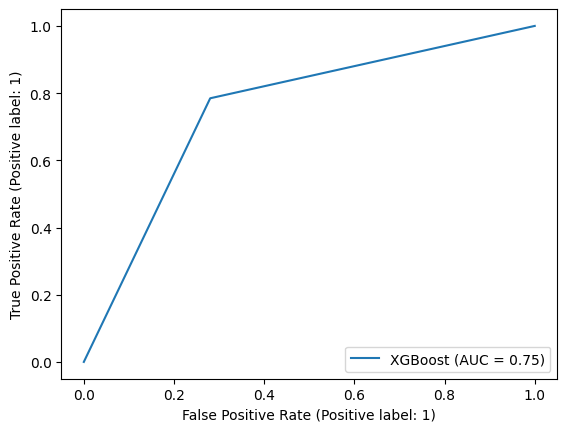

In [ ]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_teste, y_pred, name='XGBoost');

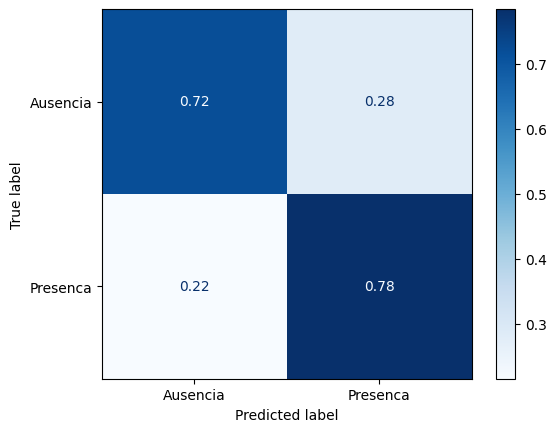

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(modelo, X_teste, y_teste, display_labels=['Ausencia', 'Presenca'],
                                      normalize='true', cmap='Blues');

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    'learning_rate': [0.1, 0.2, 0.3],
    'max_depth': [0, 2, 4, 6, 10],
    'colsample_bytree': [0.1, 0.5, 1],
    'n_estimators': [10, 25, 50]
}

modelo_xgb = xgb.XGBClassifier()

random_search_cv = RandomizedSearchCV(estimator=modelo_xgb, param_distributions=params, n_iter=10, cv=5, scoring='accuracy',
                                      verbose=1)

random_search_cv.fit(X,y)

print('Melhores parametros encontrados: ', random_search_cv.best_params_)
print('Acuracia:', random_search_cv.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Melhores parametros encontrados:  {'n_estimators': 50, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1}
Acuracia: 0.911420304814154


In [ ]:
modelo_ajustado = xgb.XGBClassifier(objective='binary:logistic', colsample_bytree=1,
                                  learning_rate=0.1, max_depth=6, n_estimators=50)

modelo_ajustado.fit(X_resampled, y_resampled)

y_pred = modelo_ajustado.predict(X_teste)

# Avaliar desempenho
class_report = classification_report(y_teste, y_pred)
print(f"Relatório de Classificação:\n{class_report}")

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.97      0.71      0.82     82338
           1       0.22      0.80      0.34      8178

    accuracy                           0.72     90516
   macro avg       0.60      0.76      0.58     90516
weighted avg       0.91      0.72      0.78     90516



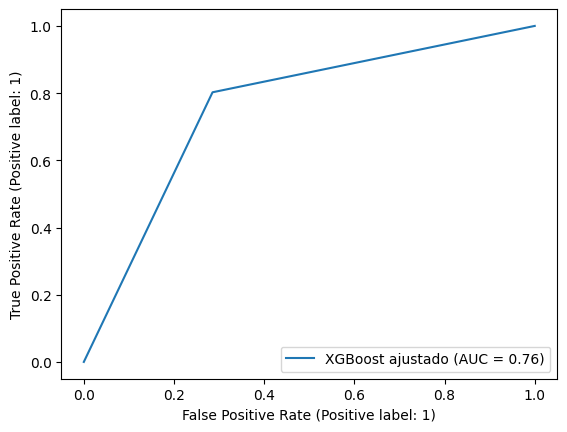

In [ ]:
RocCurveDisplay.from_predictions(y_teste, y_pred, name='XGBoost ajustado');

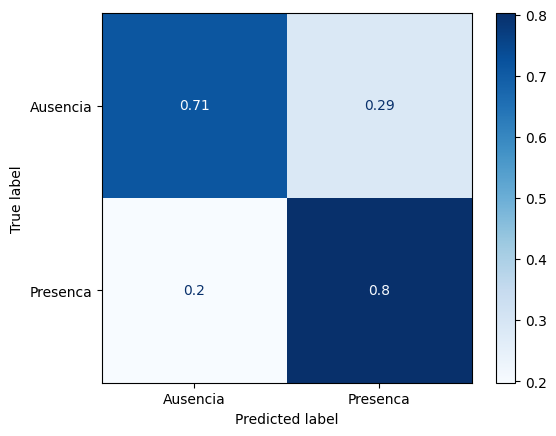

In [ ]:
ConfusionMatrixDisplay.from_estimator(modelo_ajustado, X_teste, y_teste, display_labels=['Ausencia', 'Presenca'],
                                      normalize='true', cmap='Blues');